In [2]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation
from IPython import display

import random

# ex 1


In [10]:
nrt = 1000

N = 4
f = np.zeros(N)

# strategie reject first
for t in range(nrt):
  ord = np.random.permutation(N)

  chosen = ord[0]
  f[chosen] += 1


print(f)


[229. 242. 283. 246.]


In [13]:
nrt = 10000

N = 4
f = np.zeros(N)
# strategie reject first
for t in range(nrt):
  ord = np.random.permutation(N)

  chosen = -1
  for val in ord[1:]:
    if ord[0] < val:
      chosen = val
      break

  if chosen==-1:
    chosen = ord[-1]

  f[chosen] += 1


print(f/nrt*24)

[ 1.8456  3.9648  7.164  11.0256]


In [14]:
nrt = 10000

N = 4
f = np.zeros(N)

# strategie reject first
for t in range(nrt):
  ord = np.random.permutation(N)
  nresp = 0

  thr = max(ord[0], ord[1])
  chosen = -1
  for val in ord[2:]:
    if val > thr:
      chosen = val
      break

  if chosen == -1:
    chosen = ord[-1]

  f[chosen] += 1

print(f/nrt * 24)


[3.9312 3.9984 6.1704 9.9   ]


In [17]:
nrt = 10000

N = 10
f = np.zeros(N)

# strategie reject first
for t in range(nrt):
  ord = np.random.permutation(N)
  nresp = 0

  sq = int(np.sqrt(N))
  thr = ord[0]
  for i in range(1, sq):
    if ord[i] > thr:
      thr = ord[i]

  chosen = -1
  for val in ord[sq:]:
    if val > thr:
      chosen = val
      break

  if chosen == -1:
    chosen = ord[-1]

  f[chosen] += 1

print(f/nrt)


[0.0337 0.0329 0.0311 0.0343 0.0361 0.045  0.0654 0.1142 0.2004 0.4069]


In [19]:
nrt = 10000

N = 10
f = np.zeros(N)
# strategie reject first
for t in range(nrt):
  ord = np.random.permutation(N)

  chosen = -1
  for val in ord[1:]:
    if ord[0] < val:
      chosen = val
      break

  if chosen==-1:
    chosen = ord[-1]

  f[chosen] += 1


print(f/nrt)

[0.0112 0.0217 0.0307 0.0448 0.0655 0.0902 0.1128 0.1468 0.1953 0.281 ]


In [20]:
## generalizare

In [29]:
def simulare(N, k, nrt):
  f = np.zeros(N)
  for t in range(nrt):
    ord = np.random.permutation(N)
    nresp = 0

    thr = ord[0]
    for i in range(1, k):
      if ord[i] < thr:
        thr = ord[i]

    chosen = -1
    for val in ord[k:]:
      if val < thr:
        chosen = val
        break

    if chosen == -1:
      chosen = ord[-1]

    f[chosen] += 1

  f = np.array(f)
  f = f/nrt
  return f


nrt = 10000
bestk = -1
maxi = 0
N = 100
for k in range(1, N):
  f = simulare(N, k, nrt)
  if f[0] > maxi:
    maxi = f[0]
    bestk = k
  if k % 10 == 0:
    print(k, f[0])

print()
print("best: ", bestk, maxi)




10 0.2363
20 0.3235
30 0.36
40 0.3696
50 0.3526
60 0.3109
70 0.2499
80 0.1792
90 0.0965

best:  33 0.3773


In [30]:
def simulare(N, k, nrt):
  f = np.zeros(N)
  for t in range(nrt):
    ord = np.random.permutation(N)
    nresp = 0

    thr = ord[0]
    for i in range(1, k):
      if ord[i] < thr:
        thr = ord[i]

    chosen = -1
    for val in ord[k:]:
      if val < thr:
        chosen = val
        break

    if chosen == -1:
      chosen = ord[-1]

    f[chosen] += 1

  f = np.array(f)
  f = f/nrt
  return f


nrt = 10000
bestk = -1
maxi = 0
N = 1000
for k in range(1, N):
  f = simulare(N, k, nrt)
  if f[0] > maxi:
    maxi = f[0]
    bestk = k
  if k % 10 == 0:
    print(k, f[0])

print()
print("best: ", bestk, maxi)




10 0.0457
20 0.0779
30 0.1072
40 0.1352
50 0.1492
60 0.1727
70 0.1826
80 0.2055
90 0.2183
100 0.2322
110 0.2428
120 0.2563
130 0.2683
140 0.2787
150 0.2862
160 0.29
170 0.3075
180 0.3036
190 0.3107
200 0.3144
210 0.3341
220 0.334
230 0.3384
240 0.335
250 0.3468
260 0.354
270 0.3578
280 0.3644
290 0.3581
300 0.3576
310 0.3623
320 0.3708
330 0.3651
340 0.3764
350 0.3669
360 0.3715
370 0.3726
380 0.3681
390 0.3639
400 0.3629
410 0.3622
420 0.3643
430 0.3635
440 0.366
450 0.3504
460 0.352
470 0.349


KeyboardInterrupt: 

50 150.2632761110459
100 230.70933429107282
150 284.99354078597
200 322.28798248578056
250 346.9489027794408
300 361.5420940752524
350 367.7629525029169
400 366.8164677495357
450 359.6036109830948
500 346.82371527990995
550 329.0354560973635
600 306.69546314844973
650 280.1839694985318
700 249.82252147137996
750 215.88660294993332
800 178.61487855135815
850 138.21611727898454
900 94.87448168463231
950 48.753638220802785

best:  368 368.1956


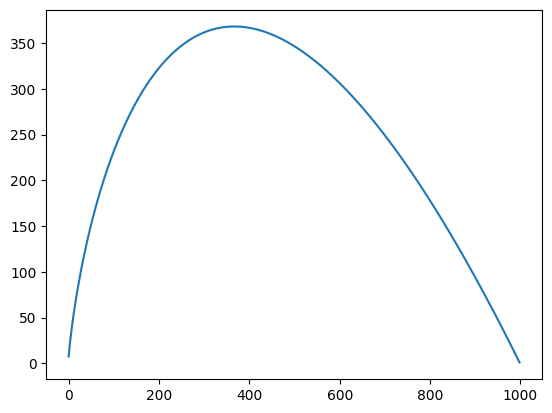

In [35]:
def simfr(N, k):
  P = 0
  for num in range(k, N):
    P += (k/num)

  return P


nrt = 10000
bestk = -1
maxi = 0
N = 1000
probs = []
for k in range(1, N):
  P = simfr(N, k)
  probs.append(P)
  if P > maxi:
    maxi = P
    bestk = k
  if k % 50 == 0:
    print(k, P)

print()
print("best: ", bestk, np.round(maxi, 4))

plt.plot(probs)
plt.show()

